# Earnings Event Engine

**A short, deterministic research demo: earnings inputs → validated event features → interpretable event and PEAD-style context.**

This is the repository's canonical offline workflow. It uses only local, schema-valid fixtures—never network data—and is deliberately framed as research plumbing rather than a trading recommendation.

> **Speaker cue (0:00–0:20):** The engine makes earnings-event research auditable: it normalizes timing, aligns the correct price sessions, attaches an explicit option-implied move, and only sends validated events into downstream analysis.

In [1]:
from __future__ import annotations

import html
import math
import os
import re
import subprocess
import sys
import tempfile
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Markdown, SVG, display

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns', 20)


def find_repo_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / 'README.md').exists() and (candidate / 'scripts' / 'run_full_research_pipeline.py').exists():
            return candidate
    raise RuntimeError('Run this notebook from inside the earnings_event_engine repository.')


def display_table(frame: pd.DataFrame, formats: dict[str, str] | None = None) -> None:
    style = (
        frame.style
        .format(formats or {}, na_rep='—')
        .hide(axis='index')
        .set_caption('')
        .set_table_styles([
            {'selector': 'th', 'props': [('background-color', '#12355b'), ('color', 'white'), ('font-weight', '600'), ('padding', '7px 10px')]},
            {'selector': 'td', 'props': [('padding', '6px 10px'), ('border-bottom', '1px solid #dce6f1')]},
            {'selector': 'table', 'props': [('font-size', '14px'), ('border-collapse', 'collapse')]},
        ])
    )
    display(style)


def run_checked(command: list[str], label: str) -> str:
    run_env = os.environ.copy()
    run_env['PYTHONWARNINGS'] = 'ignore::FutureWarning'
    completed = subprocess.run(command, cwd=ROOT, text=True, capture_output=True, env=run_env, check=False)
    if completed.returncode != 0:
        diagnostic = '\n'.join((completed.stdout + '\n' + completed.stderr).splitlines()[-30:])
        raise RuntimeError(f'{label} failed (exit {completed.returncode}).\n{diagnostic}')
    return completed.stdout


def render_move_chart(frame: pd.DataFrame) -> None:
    """Render a dependency-free SVG comparison for a recording-friendly screen."""
    values = frame[['ticker', 'realized_gap_move', 'implied_move']].copy()
    max_value = max(0.10, float(values[['realized_gap_move', 'implied_move']].max().max()) * 1.18)
    max_value = math.ceil(max_value * 20) / 20
    width, height, left, chart_width = 760, 250, 150, 530
    baseline, row_height = 75, 68
    pieces = [
        f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}" role="img">',
        '<rect width="100%" height="100%" fill="#fbfdff" rx="10"/>',
        '<text x="24" y="32" font-family="Arial, sans-serif" font-size="18" font-weight="700" fill="#12355b">Actual gap vs. option-implied move</text>',
        '<rect x="505" y="18" width="12" height="12" fill="#2b6cb0"/><text x="523" y="29" font-family="Arial, sans-serif" font-size="12" fill="#29435c">Actual gap</text>',
        '<rect x="620" y="18" width="12" height="12" fill="#e9a23b"/><text x="638" y="29" font-family="Arial, sans-serif" font-size="12" fill="#29435c">Implied</text>',
    ]
    for tick in range(3):
        value = max_value * tick / 2
        x = left + chart_width * tick / 2
        pieces.extend([
            f'<line x1="{x:.1f}" y1="54" x2="{x:.1f}" y2="220" stroke="#dce6f1" stroke-width="1"/>',
            f'<text x="{x:.1f}" y="240" text-anchor="middle" font-family="Arial, sans-serif" font-size="12" fill="#5a7188">{value:.0%}</text>',
        ])
    for index, row in values.reset_index(drop=True).iterrows():
        y = baseline + index * row_height
        actual_width = chart_width * float(row.realized_gap_move) / max_value
        implied_width = chart_width * float(row.implied_move) / max_value
        label = html.escape(str(row.ticker))
        pieces.extend([
            f'<text x="{left - 14}" y="{y + 13}" text-anchor="end" font-family="Arial, sans-serif" font-size="15" font-weight="700" fill="#12355b">{label}</text>',
            f'<rect x="{left}" y="{y}" width="{actual_width:.1f}" height="16" fill="#2b6cb0" rx="3"/>',
            f'<text x="{left + actual_width + 7:.1f}" y="{y + 13}" font-family="Arial, sans-serif" font-size="12" fill="#29435c">{float(row.realized_gap_move):.2%}</text>',
            f'<rect x="{left}" y="{y + 24}" width="{implied_width:.1f}" height="16" fill="#e9a23b" rx="3"/>',
            f'<text x="{left + implied_width + 7:.1f}" y="{y + 37}" font-family="Arial, sans-serif" font-size="12" fill="#29435c">{float(row.implied_move):.2%}</text>',
        ])
    pieces.append('</svg>')
    display(SVG(''.join(pieces)))


ROOT = find_repo_root(Path.cwd().resolve())
FIXTURE_DIR = ROOT / 'tests' / 'fixtures' / 'offline_pipeline'
TF_FIXTURE_DIR = ROOT / 'tests' / 'fixtures' / 'trading_foundation_historical_data'
RUN_DIR = Path(tempfile.mkdtemp(prefix='earnings-event-engine-demo-'))

fixture_events = pd.read_csv(FIXTURE_DIR / 'earnings_events.csv', parse_dates=['earnings_date'])
fixture_options = pd.read_csv(FIXTURE_DIR / 'options.csv', parse_dates=['event_date'])
fixture_prices = pd.read_csv(FIXTURE_DIR / 'prices.csv', parse_dates=['date'])

option_legs = (
    fixture_options.pivot_table(index=['ticker', 'event_date', 'underlying_price'], columns='option_type', values='mid', aggfunc='first')
    .reset_index()
    .rename(columns={'call': 'call_mid', 'put': 'put_mid'})
)
event_lookup = fixture_events.assign(event_date=fixture_events['earnings_date'].dt.normalize())
input_view = event_lookup.merge(option_legs, on=['ticker', 'event_date'], how='left', validate='one_to_one')
input_view['daily_price_rows'] = input_view['ticker'].map(fixture_prices.groupby('ticker').size())
input_view = input_view.assign(earnings_date=input_view['earnings_date'].dt.strftime('%Y-%m-%d'))

display(Markdown('## 1. Representative input contract'))
display(Markdown('**Local fixture only:** two earnings events, daily OHLC prices, and pre-event call/put mids. This is a schema-valid demonstration sample—not historical performance evidence.'))
display_table(input_view[['ticker', 'earnings_date', 'announcement_timing', 'daily_price_rows', 'call_mid', 'put_mid']], {'call_mid': '${:,.2f}', 'put_mid': '${:,.2f}'})


## 1. Representative input contract

**Local fixture only:** two earnings events, daily OHLC prices, and pre-event call/put mids. This is a schema-valid demonstration sample—not historical performance evidence.

ticker,earnings_date,announcement_timing,daily_price_rows,call_mid,put_mid
AAPL,2025-01-30,AMC,13,$4.80,$4.70
MSFT,2025-02-05,BMO,13,$5.20,$5.10


## 2. Run the audited workflow

`earnings events + daily prices + call/put mids` → **normalize timing** → **align pre/post sessions** → **validate and enrich** → `validated_features.parquet` → descriptive research stages.

The notebook invokes the documented canonical CLI, so it exercises the same artifact contract as the test-backed workflow. Invalid rows stay visible in the feature audit; required downstream stages use only the validated artifact.

> **Speaker cue (0:20–1:15):** Here the key design choice is validation before analysis. The fixture run is deterministic and offline, but it calls the real orchestrator—not notebook reimplementations.

In [2]:
pipeline_stdout = run_checked(
    [
        sys.executable,
        str(ROOT / 'scripts' / 'run_full_research_pipeline.py'),
        '--fixture-dir', str(FIXTURE_DIR),
        '--output-dir', str(RUN_DIR),
    ],
    'Canonical fixture pipeline',
)

if 'FINAL STATUS: SUCCESS' not in pipeline_stdout:
    raise RuntimeError('The canonical pipeline returned without a success status.')

stage_records = re.findall(r'\[SUCCESS\] ([^:]+): (.+)', pipeline_stdout)
expected_stages = {'event_pipeline', 'earnings_analysis', 'strategy_simulation', 'conditional_analysis'}
if {stage for stage, _ in stage_records} != expected_stages:
    raise RuntimeError(f'Unexpected canonical stage results: {stage_records}')

artifact_specs = [
    ('events.parquet', 'normalized raw events'),
    ('clean_events.parquet', 'validated event rows'),
    ('features.parquet', 'feature-level audit trail'),
    ('validated_features.parquet', 'only input to required downstream research'),
    ('diagnostics.parquet', 'coverage and failure diagnostics'),
]
artifact_view = []
for filename, purpose in artifact_specs:
    artifact_path = RUN_DIR / filename
    if not artifact_path.exists():
        raise RuntimeError(f'Expected artifact is missing: {filename}')
    artifact_view.append({'artifact': filename, 'rows': len(pd.read_parquet(artifact_path)), 'purpose': purpose})

display(Markdown('### Canonical run: success'))
display_table(pd.DataFrame([{'stage': stage, 'status': 'SUCCESS', 'result': detail} for stage, detail in stage_records]))
display_table(pd.DataFrame(artifact_view))

features = pd.read_parquet(RUN_DIR / 'features.parquet')
clean_events = pd.read_parquet(RUN_DIR / 'clean_events.parquet')
validated_features = pd.read_parquet(RUN_DIR / 'validated_features.parquet')
assert len(features) >= len(validated_features) > 0
assert set(validated_features['event_id']) == set(clean_events['event_id'])


### Canonical run: success

stage,status,result
event_pipeline,SUCCESS,raw_events=2 clean_events=2 feature_rows=2 validated_feature_rows=2
earnings_analysis,SUCCESS,by_ticker_rows=2 by_timing_rows=2
strategy_simulation,SUCCESS,simulation_rows=2 ticker_breakdown_rows=2
conditional_analysis,SUCCESS,group_rows=2 timing_rows=2


artifact,rows,purpose
events.parquet,2,normalized raw events
clean_events.parquet,2,validated event rows
features.parquet,2,feature-level audit trail
validated_features.parquet,2,only input to required downstream research
diagnostics.parquet,28,coverage and failure diagnostics


## 3. Read the result: event reaction, option context, and PEAD-style follow-through

The **actual gap** is the aligned pre-close to post-open move. The **implied move** comes from the fixture's explicit call and put mids: `(call mid + put mid) / underlying price`. The HV20 proxy remains separate.

The final table is produced by the separate PEAD research CLI from the validated artifact and local Trading_Foundation-style EOD fixture. It reports coverage and conservatively refuses a signal decision when the sample is too small.

> **Speaker cue (1:15–2:30):** This is the useful research output: every event is traceable to its aligned prices and option inputs. The comparison is descriptive, while the PEAD step checks whether there is enough forward-return coverage to justify further study.

### Validated event result

ticker,event_date,announcement_timing,pre_close,post_open,actual_gap,call_mid,put_mid,implied_move,surprise_vs_implied
AAPL,2025-01-30,AMC,$106.00,$108.40,2.26%,$4.80,$4.70,9.09%,-6.83%
MSFT,2025-02-05,BMO,$205.00,$205.70,0.34%,$5.20,$5.10,4.90%,-4.56%


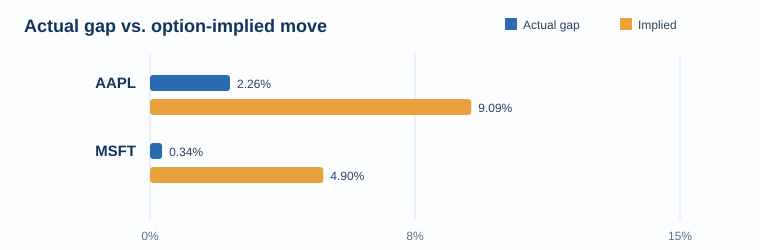

### PEAD-style 1-day follow-through

ticker,announcement_timing,reaction_return,forward_return_1d,reaction_bucket
MSFT,BMO,0.59%,0.39%,positive_reaction


window_days,usable_events,status,reason
1,1,not_defensible,Only 1 usable events at 1d; require at least 30 before considering watchlist or signal design.


**Research boundary:** the fixture produces one usable 1-day observation, below the engine’s 30-event review threshold. It demonstrates honest coverage reporting—not a PEAD signal or trading claim.

In [3]:
validated = validated_features.copy()
validated['event_date'] = pd.to_datetime(validated['event_date']).dt.normalize()
reaction_view = validated.merge(option_legs, on=['ticker', 'event_date'], how='left', validate='one_to_one')
reaction_view['fixture_implied_move_check'] = (reaction_view['call_mid'] + reaction_view['put_mid']) / reaction_view['underlying_price']
if not np.isclose(reaction_view['implied_move'], reaction_view['fixture_implied_move_check']).all():
    raise RuntimeError('The option-implied move contract did not reconcile to the input call/put mids.')

event_result = reaction_view.assign(
    event_date=reaction_view['event_date'].dt.strftime('%Y-%m-%d'),
    actual_gap=reaction_view['realized_gap_move'],
)
display(Markdown('### Validated event result'))
display_table(
    event_result[['ticker', 'event_date', 'announcement_timing', 'pre_close', 'post_open', 'actual_gap', 'call_mid', 'put_mid', 'implied_move', 'surprise_vs_implied']],
    {'pre_close': '${:,.2f}', 'post_open': '${:,.2f}', 'actual_gap': '{:.2%}', 'call_mid': '${:,.2f}', 'put_mid': '${:,.2f}', 'implied_move': '{:.2%}', 'surprise_vs_implied': '{:.2%}'},
)
render_move_chart(reaction_view)

PEAD_DIR = RUN_DIR / 'pead'
run_checked(
    [
        sys.executable, str(ROOT / 'scripts' / 'run_pead_research.py'),
        '--events-path', str(RUN_DIR / 'validated_features.parquet'),
        '--historical-data-root', str(TF_FIXTURE_DIR),
        '--output-dir', str(PEAD_DIR), '--windows', '1',
    ],
    'PEAD research workflow',
)
pead_events = pd.read_csv(PEAD_DIR / 'pead_event_returns.csv')
pead_readiness = pd.read_csv(PEAD_DIR / 'pead_signal_assessment.csv')
pead_view = pead_events.loc[pead_events['forward_return_1d'].notna(), ['ticker', 'announcement_timing', 'reaction_return', 'forward_return_1d', 'reaction_bucket']].copy()

display(Markdown('### PEAD-style 1-day follow-through'))
display_table(pead_view, {'reaction_return': '{:.2%}', 'forward_return_1d': '{:.2%}'})
display_table(pead_readiness[['window_days', 'usable_events', 'status', 'reason']])
assert pead_readiness['status'].eq('not_defensible').all()
display(Markdown('**Research boundary:** the fixture produces one usable 1-day observation, below the engine’s 30-event review threshold. It demonstrates honest coverage reporting—not a PEAD signal or trading claim.'))


## Closing takeaway

The strongest completed workflow is the reproducible **validated-event artifact**: raw inputs are normalized, timing and price alignment are checked, event-time option context is explicit, and downstream analysis is gated to validated rows.

For live research, replace the fixture with audited earnings, daily-bar, and pre-event historical option-snapshot coverage; preserve the same artifact contract and keep historical option P&L claims out of scope until entry/exit premium data is modeled.

> **Speaker cue (2:30–2:50):** The value is not a two-event conclusion. It is a reusable, test-backed event-research boundary that makes stronger data and larger samples easier to audit.